# Online Retail – Exploratory Data Analysis

## 1. Project Overview

In this project I explore the **Online Retail** dataset from the UCI Machine Learning Repository. It contains the recorded transactions of a UK-based online retailer that mainly sells gifts, between **1 December 2010 and 9 December 2011**.

The goal is exploratory. I want to understand who the customers are, which products sell, how sales change over time and across countries, and how unit prices are distributed. I also point out where the data is unusual or limited. This notebook does **not** clean the data for modeling and does not build any model.

### How terms are used in this notebook

- **Record / line item:** one row of the DataFrame (one product line). A row is *not* an invoice.
- **LineTotal:** `Quantity * UnitPrice` for a single row.
- **Revenue / spending:** the sum of `LineTotal` over a group of rows (a customer, a product, a month, a country...). Unless stated otherwise, rows with negative quantities are included, so these are *net recorded values*, not confirmed accounting revenue.
- **Currency:** the dataset documentation lists `UnitPrice` in sterling, so monetary values are in £.

### Rows used in each analysis

| Analysis | Rows used |
|---|---|
| Customer | Rows with a non-missing `CustomerID` (negative quantities included) |
| Product | Rows with a non-missing `Description` **and** `Quantity > 0` (`UnitPrice` is not filtered) |
| Monthly, weekday and hourly | All rows (negative quantities included) |
| Country | All rows (negative quantities included) |
| Unit price | All rows |

No rows are removed from the DataFrame at any point. Each analysis only selects the rows it needs.

### Notebook contents

1. Project Overview
2. Dataset Overview
3. Initial Data Exploration
4. Data Quality Assessment (missing values, duplicate rows, negative quantities)
5. Customer Analysis
6. Product Analysis
7. Time-Based Analysis
8. Geographical Analysis
9. Unit Price Analysis
10. Key Findings
11. Limitations
12. Final Conclusion


## 2. Dataset Overview

The data is loaded directly from the UCI repository with the `ucimlrepo` package. The package returns the data as `features` and `targets`. This dataset has no target column, so only `features` is used.

In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from ucimlrepo import fetch_ucirepo

# Fetch the dataset
online_retail = fetch_ucirepo(id=352)

# Features as a DataFrame. .copy() makes sure new columns added later
# are not written to a view of the original object.
df = online_retail.data.features.copy()

# Metadata and variable information
print(online_retail.metadata)
print(online_retail.variables)

{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

**Important limitation:** the full dataset has eight columns, but the `features` DataFrame retrieved here has only six: `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID` and `Country`. `InvoiceNo` and `StockCode` are listed in the metadata as index columns and are not part of this DataFrame. This means that in this notebook:

- Each row is a product line. I cannot count actual invoices or orders, measure purchase frequency, or identify cancellations.
- Products are identified by `Description`, not by product code, so I cannot count unique product codes.

## 3. Initial Data Exploration

A first look at the structure, data types and basic statistics of the DataFrame.

In [4]:
print("Features type:", type(df))
print("Features shape:", df.shape)

print("\nTargets:", online_retail.data.targets)

print("\nFeatures columns:")
print(df.columns.tolist())

display(df.head())

Features type: <class 'pandas.core.frame.DataFrame'>
Features shape: (541909, 6)

Targets: None

Features columns:
['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB


In [6]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


### Initial Observations

- The DataFrame has 541,909 rows and 6 columns. `InvoiceDate` is stored as text (`object`), so it is converted to datetime in the time-based analysis.
- `Quantity` ranges from -80,995 to 80,995 and `UnitPrice` ranges from -11,062.06 to 38,970. Both columns contain negative values.
- Both columns are strongly right-skewed: the mean quantity (9.55) is well above the median (3), and the mean unit price (4.61) is above the median (2.08). The standard deviations are much larger than the means.
- `CustomerID` has 406,829 non-null values, so it is missing for part of the dataset (see the next section).

### Creating `LineTotal`

In [7]:
# Value of one row (product line): Quantity * UnitPrice, in £
df['LineTotal'] = df['Quantity'] * df['UnitPrice']

`LineTotal` is the value of a single line item, **not** an invoice total. It is negative when `Quantity` is negative, and it is zero or negative when `UnitPrice` is zero or negative, even if `Quantity` is positive. Summing it gives a *net recorded value*, which is what "revenue" and "spending" mean in the rest of this notebook.

## 4. Data Quality Assessment

First I check for missing values, duplicate rows and rows with negative quantities. Unusual prices are examined in the Unit Price section.

In [8]:
df.isnull().sum()

Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
LineTotal           0
dtype: int64

### Duplicate Rows

Rows that are identical across all six original columns are counted below. They are **not removed**. Without `InvoiceNo`, an identical row could be a legitimate repeated product line within an invoice or a double entry, and this data cannot tell which.

In [9]:
original_columns = ['Description', 'Quantity', 'InvoiceDate',
                    'UnitPrice', 'CustomerID', 'Country']

duplicate_rows = df.duplicated(subset=original_columns)

print("Rows identical to an earlier row (six original columns):", duplicate_rows.sum())
print("Share of all rows (%):", round(duplicate_rows.mean() * 100, 2))

Rows identical to an earlier row (six original columns): 6007
Share of all rows (%): 1.11


### Negative Quantities

Negative `Quantity` values may represent returns, cancellations or adjustments, but `InvoiceNo` (where a cancellation is marked) is not available, so they cannot be confirmed as cancellations. The table below shows how much these rows contribute, so it is clear how much the net values used in this notebook depend on including them.

In [10]:
negative_qty = df['Quantity'] < 0

negative_qty_summary = pd.DataFrame({
    'Rows': [negative_qty.sum(), (~negative_qty).sum()],
    'Share of rows (%)': [negative_qty.mean() * 100, (~negative_qty).mean() * 100],
    'Sum of Quantity': [df.loc[negative_qty, 'Quantity'].sum(),
                        df.loc[~negative_qty, 'Quantity'].sum()],
    'Sum of LineTotal (£)': [df.loc[negative_qty, 'LineTotal'].sum(),
                             df.loc[~negative_qty, 'LineTotal'].sum()]
}, index=['Quantity < 0', 'Quantity >= 0'])

display(negative_qty_summary.round(2))
print("Net LineTotal, all rows (£):", round(df['LineTotal'].sum(), 2))

,Rows,Share of rows (%),Sum of Quantity,Sum of LineTotal (£)
Quantity < 0,10624,1.96,-484531,-896812.49
Quantity >= 0,531285,98.04,5660981,10644560.42


Net LineTotal, all rows (£): 9747747.93


### Data Quality Findings

- `Description` has **1,454** missing values (about 0.27%).
- `CustomerID` has **135,080** missing values (about 24.93%).
- The dataset metadata marks every column as having no missing values. That does not match the actual counts above, so I rely on the counts.
- Duplicate rows and negative quantities are counted above and **not removed**. The duplicate count uses only the six available columns, so identical rows cannot be classified as errors or as legitimate repeated lines. The negative-quantity table shows how far the net values differ from the positive-quantity-only values.
- `Quantity` and `UnitPrice` contain negative values (see `describe()` above). Zero and negative unit prices are looked at in the Unit Price section.
- Nothing is removed. Rows with a missing `CustomerID` are only left out of the customer analysis, and rows with a missing `Description` are only left out of the product analysis.

## 5. Customer Analysis

Which customers are the most active, and which ones have the highest spending?

This section only uses rows with a non-missing `CustomerID`, and negative quantities are included. Customer activity is measured by the **number of line items** (rows), not by the number of invoices, because `InvoiceNo` is not available.

In [11]:
print("Unique Customers:", df['CustomerID'].nunique())

print("Missing Customer IDs:", df['CustomerID'].isna().sum())

Unique Customers: 4372
Missing Customer IDs: 135080


In [12]:
customer_line_items = df['CustomerID'].value_counts()
top_10_customers = customer_line_items.head(10)

display(top_10_customers)

CustomerID
17841.0    7983
14911.0    5903
14096.0    5128
12748.0    4642
14606.0    2782
15311.0    2491
14646.0    2085
13089.0    1857
13263.0    1677
14298.0    1640
Name: count, dtype: int64

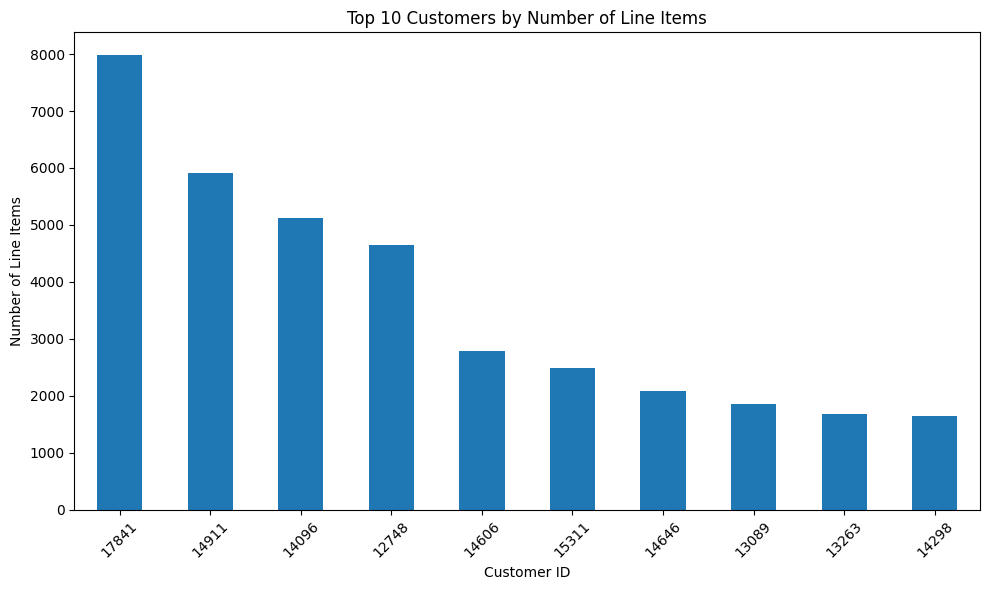

In [13]:
plt.figure(figsize=(10, 6))

# Customer IDs are floats because of the missing values, so they are shown as integers here
top_10_customers.rename(index=int).plot(kind='bar')

plt.title('Top 10 Customers by Number of Line Items')
plt.xlabel('Customer ID')
plt.ylabel('Number of Line Items')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Customer Activity Insights

- There are **4,372** unique customers. **135,080** rows (24.93%) have no `CustomerID`, and the other **406,829** rows (75.07%) are used here.
- On average, an identified customer has about 93 line items (406,829 / 4,372). The top 10 customers have between 1,640 and 7,983 line items each, so the most active customers are far above the average. I only looked at the top 10, not the full distribution.
- Customer 17841 has the most line items (7,983).

**Notes:** a line item is a product line, not an order. A customer with many line items could have placed many small orders or a few large ones, and I cannot tell which without `InvoiceNo`. Rows without a `CustomerID` are excluded from this section, not removed from the dataset. I did not investigate why they are missing, but some of the highest-priced rows in the Unit Price section (for example `AMAZON FEE` and `Adjust bad debt`) have no `CustomerID`.

In [14]:
customer_spending = (
    df.groupby('CustomerID')['LineTotal']
    .sum()
    .sort_values(ascending=False)
)

top_10_spending_customers = customer_spending.head(10)

display(top_10_spending_customers)

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187482.17
14911.0    132572.62
12415.0    123725.45
14156.0    113384.14
17511.0     88125.38
16684.0     65892.08
13694.0     62653.10
15311.0     59419.34
Name: LineTotal, dtype: float64

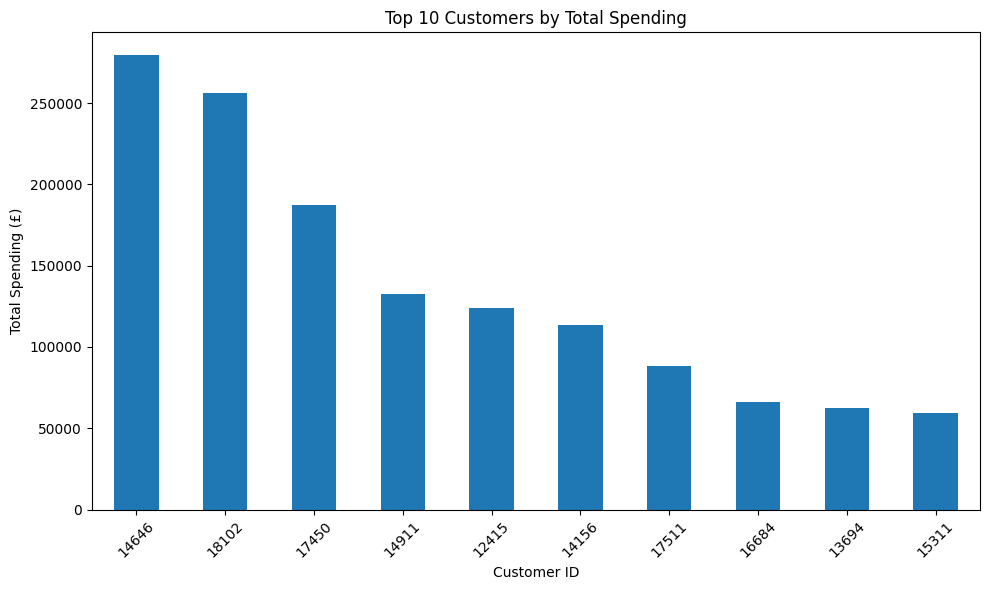

In [15]:
plt.figure(figsize=(10, 6))

top_10_spending_customers.rename(index=int).plot(kind='bar')

plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Customer ID')
plt.ylabel('Total Spending (£)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Top Spending Customers

- Customer **14646** recorded the highest net spending, totaling **279,489.02**.
- Customer **18102** ranked second with **256,438.49**.
- Customer **17450** ranked third with **187,482.17**.
- Spending varies considerably within the top 10, from about 279 thousand down to about 59 thousand.
- **The customers with the most line items are not necessarily the highest spenders.** Only three customers (14646, 14911 and 15311) appear in both top 10 lists, and customer 17841, who has the most line items, is not among the top 10 spenders. Activity and spending value are two different things.

*Note: spending is the sum of `Quantity * UnitPrice`, including negative quantities. It is a net recorded value before any investigation of cancellations and returns, and it can include non-product lines such as postage or manual entries.*

## 6. Product Analysis

Which products sell the most units, which bring in the most revenue, and which sell very little?

**Rows used:** only rows with a non-missing `Description` and `Quantity > 0`. Products are grouped by `Description`, not by product code, so one product written with different descriptions would appear as separate items.

Two things to keep in mind:

- Filtering `Quantity > 0` does **not** guarantee a positive `UnitPrice`. Zero and negative prices are still in this data, so `LineTotal` can be zero or negative here too.
- The descriptions include non-product entries such as postage, manual entries and adjustments, so they appear in the rankings as if they were products.

In [16]:
product_data = df[
    df['Description'].notna() &
    (df['Quantity'] > 0)
].copy()

In [17]:
# Total units sold per product description (used for the top and low-selling analyses)
product_sales = product_data.groupby('Description')['Quantity'].sum()

In [18]:
top_selling_products = product_sales.sort_values(ascending=False).head(10)

display(top_selling_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48478
WHITE HANGING HEART T-LIGHT HOLDER    37895
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

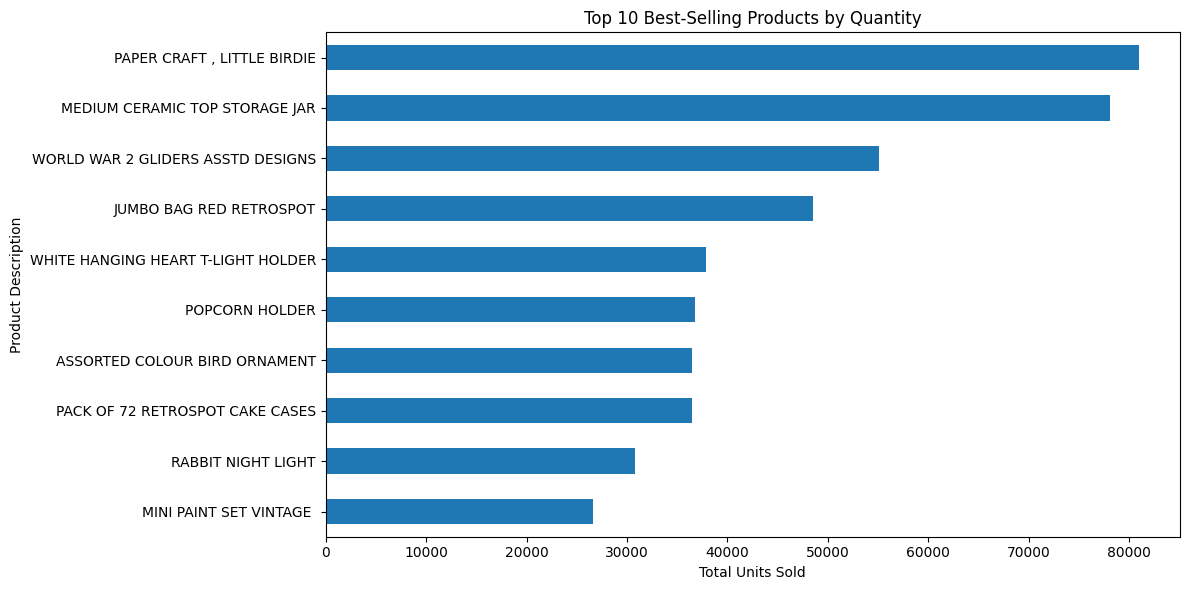

In [19]:
plt.figure(figsize=(12, 6))

top_selling_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products by Quantity')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()

In [20]:
product_revenue = (
    product_data.groupby('Description')['LineTotal']
    .sum()
    .sort_values(ascending=False)
)

top_10_revenue_products = product_revenue.head(10)

display(top_10_revenue_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: LineTotal, dtype: float64

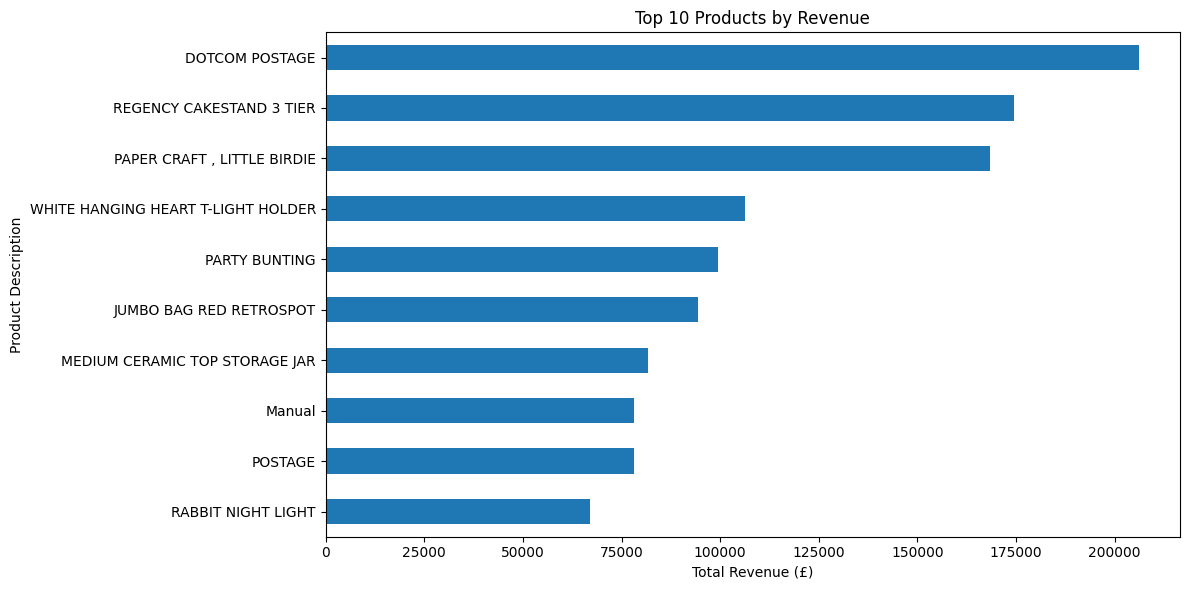

In [21]:
plt.figure(figsize=(12, 6))

top_10_revenue_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()

### Product Sales and Revenue Insights

- `PAPER CRAFT , LITTLE BIRDIE` ranks first in sales quantity (**80,995 units**) but third in revenue (**168,469.60**). Its total equals the largest single `Quantity` in the dataset, so it comes from one line item. The smallest `Quantity` in the dataset is exactly -80,995, which may be a matching reversal of this line, but I cannot confirm that without `InvoiceNo`. Negative quantities are not part of the product data, so any reversal is not reflected in this ranking.
- `DOTCOM POSTAGE` has the highest recorded revenue (**206,248.77**), but it is a postage charge, not a conventional product. `Manual` and `POSTAGE` are also in the top 10 by revenue, so 3 of the 10 entries are non-product lines.
- `REGENCY CAKESTAND 3 TIER` ranks second in revenue (**174,484.74**) even though it is not among the top 10 products by quantity.
- Quantity and revenue rankings differ because products have different unit prices, so sales volume alone does not determine revenue.

**Note:** revenue here uses positive-quantity rows only and is grouped by product description. Service-related entries such as postage are included.

### Lowest Revenue Descriptions

The same revenue table, looking at the bottom 10 instead of the top 10.

In [22]:
bottom_10_revenue_products = product_revenue.tail(10)

display(bottom_10_revenue_products)

Description
amazon adjust                              0.00
rcvd be air temp fix for dotcom sit        0.00
wrongly coded 23343                        0.00
TRAVEL CARD WALLET DOTCOMGIFTSHOP          0.00
website fixed                              0.00
wrongly coded 20713                        0.00
wrongly marked 23343                       0.00
wrongly marked                             0.00
wrongly sold (22719) barcode               0.00
Adjust bad debt                       -11062.06
Name: LineTotal, dtype: float64

Even though only rows with `Quantity > 0` are used, the bottom of the ranking contains descriptions with zero revenue (zero `UnitPrice`) and one with negative revenue, `Adjust bad debt` (-11,062.06, caused by negative unit prices). These look like administrative entries (for example `wrongly coded 23343` or `website fixed`), not normal products. I kept them in `product_data` so the product definition stays the same as above. They do not change the top 10 rankings: zero-price rows add nothing to a total, and the only two negative-price rows in the dataset both belong to `Adjust bad debt` (see the Unit Price section).

### Low-Selling Products

To define "low-selling", I look at the distribution of total units sold per product description.

In [23]:
print("Total unique products:", product_sales.count())
print("\nSales quantity statistics:")
display(product_sales.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
))

print("\nNumber of products by sales quantity:")
display(product_sales.value_counts().head(10))

Total unique products: 4077

Sales quantity statistics:


count     4077.000000
mean      1380.533235
std       3453.951223
min          1.000000
10%         10.000000
25%         54.000000
50%        349.000000
75%       1361.000000
90%       3377.600000
max      80995.000000
Name: Quantity, dtype: float64


Number of products by sales quantity:


Quantity
1     69
2     69
4     47
3     46
12    45
5     42
8     37
10    36
6     35
24    28
Name: count, dtype: int64

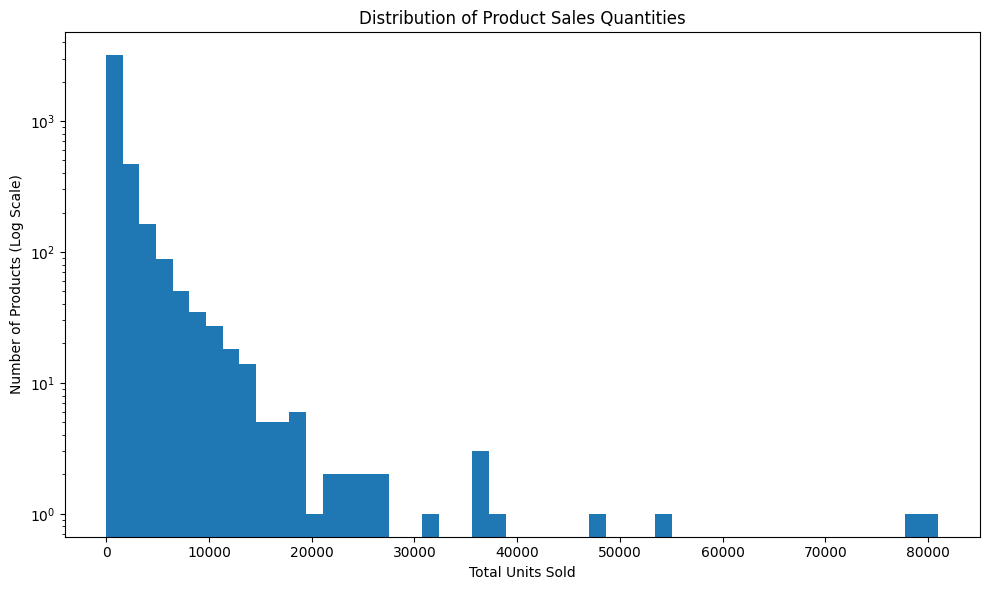

In [24]:
plt.figure(figsize=(10, 6))

plt.hist(product_sales, bins=50, log=True)

plt.title('Distribution of Product Sales Quantities')
plt.xlabel('Total Units Sold')
plt.ylabel('Number of Products (Log Scale)')
plt.tight_layout()
plt.show()

In [25]:
# Exploratory threshold: the 10th percentile of total units sold per product.
# kind='stable' breaks ties alphabetically by description, so the lists below are reproducible.
low_sales_threshold = product_sales.quantile(0.10)

low_selling_products = (
    product_sales[product_sales <= low_sales_threshold]
    .sort_values(kind='stable')
)

print("Low sales threshold:", low_sales_threshold)
print("Number of low-selling products:", len(low_selling_products))
print("Percentage of products:",
      round(len(low_selling_products) / len(product_sales) * 100, 2), "%")

display(low_selling_products.head(20))

Low sales threshold: 10.0
Number of low-selling products: 424
Percentage of products: 10.4 %


Description
 I LOVE LONDON MINI RUCKSACK          1
*Boombox Ipod Classic                 1
Amazon Adjustment                     1
BAROQUE BUTTERFLY EARRINGS MONTANA    1
BAROQUE BUTTERFLY EARRINGS RED        1
BLACK GLASS/SHELL/PEARL NECKLACE      1
BLACKCHRISTMAS TREE 30CM              1
BLOSSOM IMAGES SCRAP BOOK SET         1
BLUE CRYSTAL BOOT PHONE CHARM         1
BLUE DROP EARRINGS W BEAD CLUSTER     1
BLUE NEW BAROQUE FLOCK CANDLESTICK    1
BLUE PADDED SOFT MOBILE               1
BLUE/NAT SHELL NECKLACE W PENDANT     1
CAKE STAND LACE WHITE                 1
CAMOUFLAGE DOG COLLAR                 1
CAPIZ CHANDELIER                      1
COUNTRY COTTAGE  DOORSTOP GREEN       1
CROCHET LILAC/RED BEAR KEYRING        1
DOLPHIN WINDMILL                      1
DUSTY PINK CHRISTMAS TREE 30CM        1
Name: Quantity, dtype: int64

### Lowest-Selling Products in Detail

The table and charts below list the lowest sellers. 69 descriptions sold exactly one unit, so every bar in these charts has the same length: they show *which* descriptions are at the bottom, not differences in their volume. Ties are broken alphabetically, which has no business meaning.

In [26]:
# 30 lowest-selling product descriptions by total units sold
bottom_30_products = product_sales.sort_values(kind='stable').head(30)

display(bottom_30_products)

Description
 I LOVE LONDON MINI RUCKSACK           1
*Boombox Ipod Classic                  1
Amazon Adjustment                      1
BAROQUE BUTTERFLY EARRINGS MONTANA     1
BAROQUE BUTTERFLY EARRINGS RED         1
BLACK GLASS/SHELL/PEARL NECKLACE       1
BLACKCHRISTMAS TREE 30CM               1
BLOSSOM IMAGES SCRAP BOOK SET          1
BLUE CRYSTAL BOOT PHONE CHARM          1
BLUE DROP EARRINGS W BEAD CLUSTER      1
BLUE NEW BAROQUE FLOCK CANDLESTICK     1
BLUE PADDED SOFT MOBILE                1
BLUE/NAT SHELL NECKLACE W PENDANT      1
CAKE STAND LACE WHITE                  1
CAMOUFLAGE DOG COLLAR                  1
CAPIZ CHANDELIER                       1
COUNTRY COTTAGE  DOORSTOP GREEN        1
CROCHET LILAC/RED BEAR KEYRING         1
DOLPHIN WINDMILL                       1
DUSTY PINK CHRISTMAS TREE 30CM         1
Dotcomgiftshop Gift Voucher £100.00    1
EASTER CRAFT IVY WREATH WITH CHICK     1
ETCHED GLASS STAR TREE DECORATION      1
FILIGREE DIAMANTE CHAIN                1
FIRE

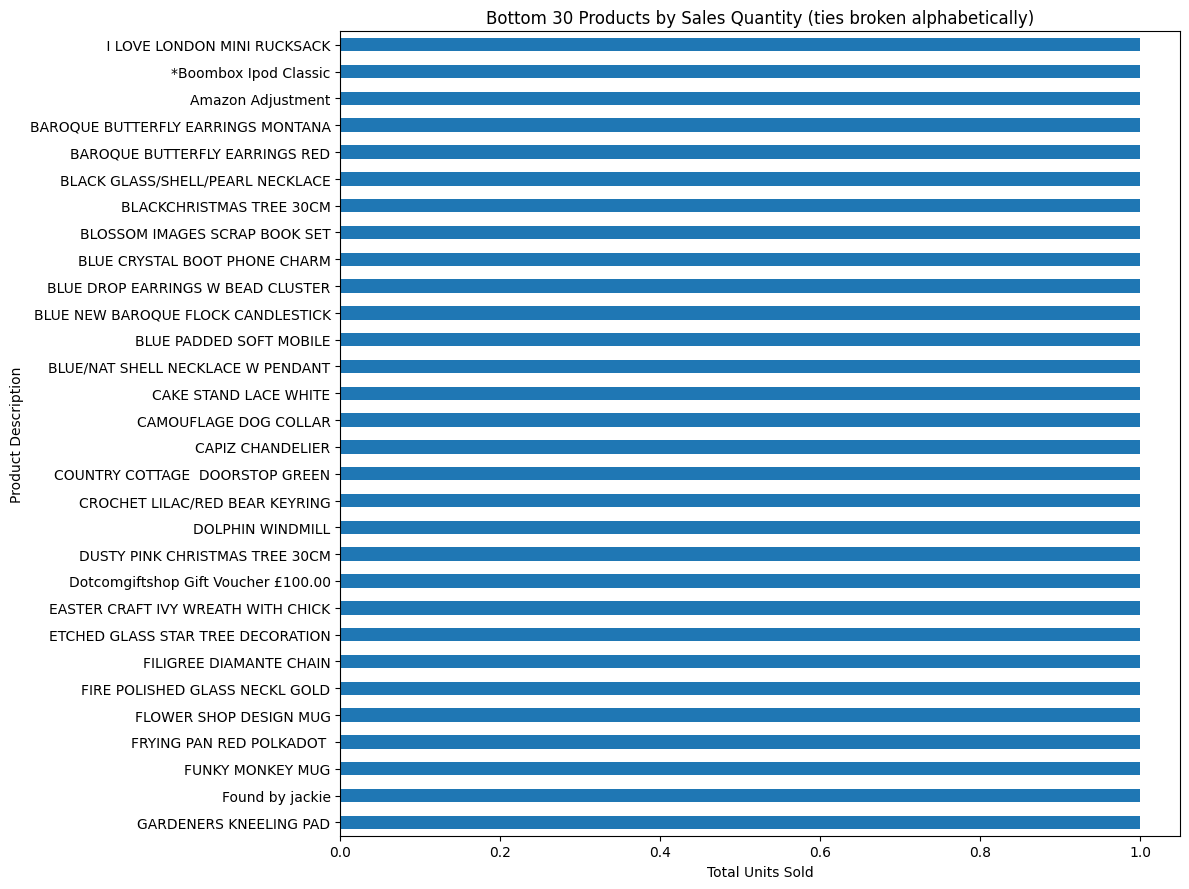

In [27]:
plt.figure(figsize=(12, 9))

bottom_30_products.plot(kind='barh')
plt.gca().invert_yaxis()

plt.title('Bottom 30 Products by Sales Quantity (ties broken alphabetically)')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

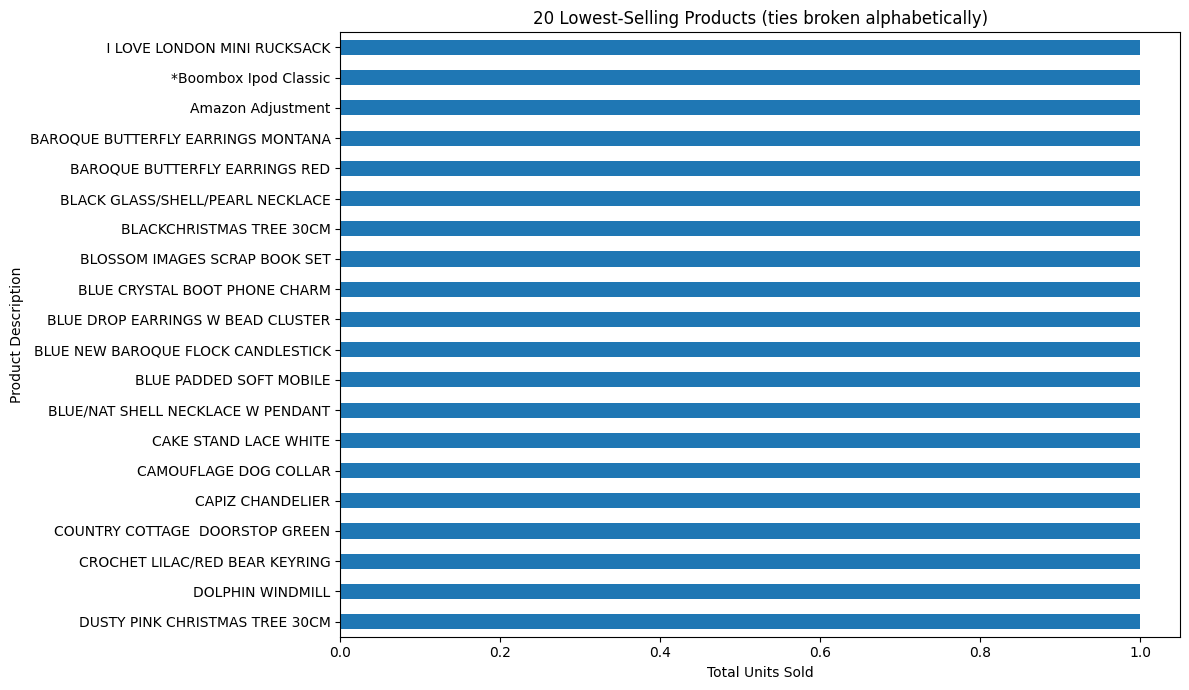

In [28]:
plt.figure(figsize=(12, 7))

low_selling_products.head(20).plot(kind='barh')
plt.gca().invert_yaxis()

plt.title('20 Lowest-Selling Products (ties broken alphabetically)')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

### Low-Selling Products Insights

- Out of 4,077 unique product descriptions, 424 products (10.4%) recorded sales of 10 units or fewer.
- The 10th percentile of product sales quantity is 10 units. Many products tie at this value, which is why slightly more than 10% of the products are included.
- 69 products recorded only one unit sold. Because of these ties, any list of "the lowest N" products is an arbitrary subset, not a ranking. To keep the tables and charts reproducible, ties are broken alphabetically by description. The 20 lowest and the bottom 30 are therefore consistent with each other, but the ordering has no business meaning.
- The low-selling group includes non-product descriptions such as `Amazon Adjustment` and `for online retail orders` (each with 1 unit), although they may not be among the 20 or 30 shown.
- Low sales volume does not necessarily mean poor product performance. Pricing, seasonality, product availability and the date a product was introduced have not been investigated.

**Note:** the low-sales threshold is an exploratory statistical criterion, not a definitive business classification.

## 7. Time-Based Analysis

How do revenue and quantity change over months, weekdays and hours of the day?

All rows are used here, including negative quantities, so the values are net recorded values. First, `InvoiceDate` is converted to a datetime. The timestamps are used as recorded, because no time zone is given.

In [29]:
df['InvoiceDate_dt'] = pd.to_datetime(
    df['InvoiceDate'],
    errors='coerce'
)

print("Date range:")
print("Start:", df['InvoiceDate_dt'].min())
print("End:", df['InvoiceDate_dt'].max())

print("\nMissing dates after conversion:")
print(df['InvoiceDate_dt'].isna().sum())

print("\nData type:")
print(df['InvoiceDate_dt'].dtype)

Date range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Missing dates after conversion:
0

Data type:
datetime64[ns]


The data ends on **9 December 2011**, so **December 2011 is an incomplete month** (only the first nine days). Its monthly values cannot be compared with full months.

### Monthly Revenue and Quantity

In [30]:
monthly_revenue = (
    df.groupby(df['InvoiceDate_dt'].dt.to_period('M'))['LineTotal']
    .sum()
)

display(monthly_revenue.to_frame())

,LineTotal
InvoiceDate_dt,
2010-12,748957.020
2011-01,560000.260
2011-02,498062.650
2011-03,683267.080
2011-04,493207.121
2011-05,723333.510
2011-06,691123.120
2011-07,681300.111
2011-08,682680.510


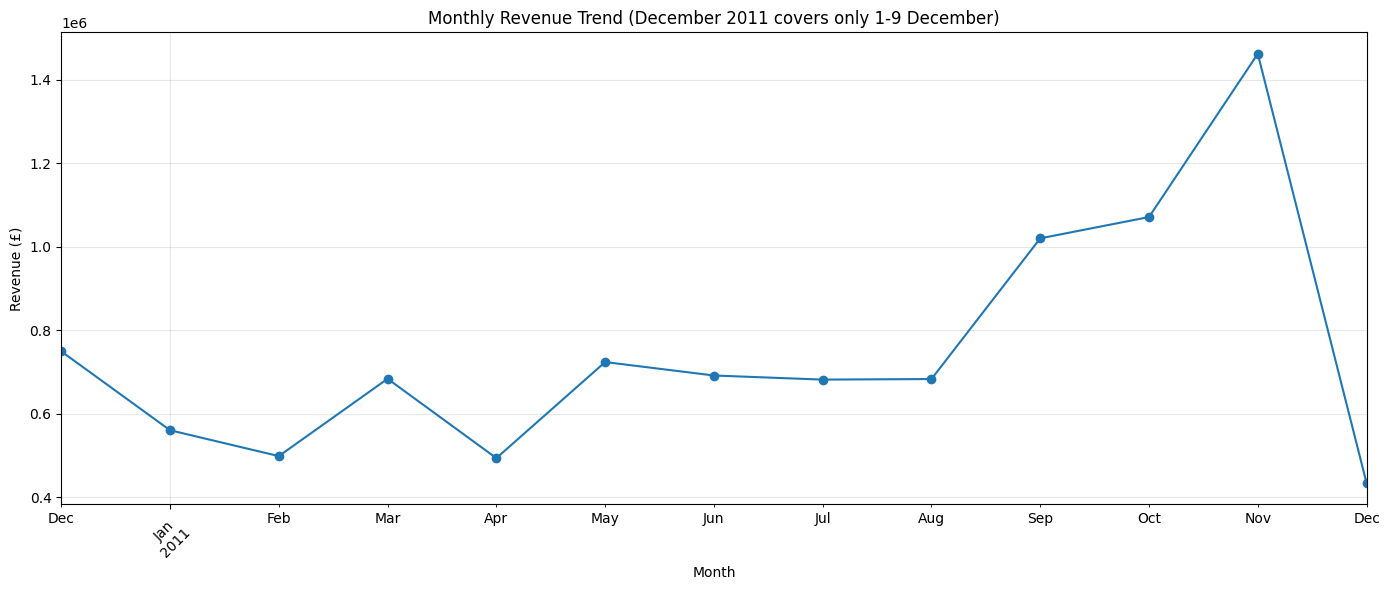

In [31]:
plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend (December 2011 covers only 1-9 December)')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Monthly Revenue Insights

- Revenue fluctuated during the first four months of 2011.
- Monthly revenue remained relatively stable between May and August.
- A significant increase occurred from September to November.
- November recorded the highest monthly revenue, approximately 1.46 million.
- December 2011 looks low only because the data covers just its first nine days.

**Note:** monthly values are the sum of recorded line totals, including negative quantities. They should not be read as confirmed accounting revenue.

In [32]:
monthly_quantity = (
    df.groupby(df['InvoiceDate_dt'].dt.to_period('M'))['Quantity']
    .sum()
)

display(monthly_quantity.to_frame())

,Quantity
InvoiceDate_dt,
2010-12,342228
2011-01,308966
2011-02,277989
2011-03,351872
2011-04,289098
2011-05,380391
2011-06,341623
2011-07,391116
2011-08,406199


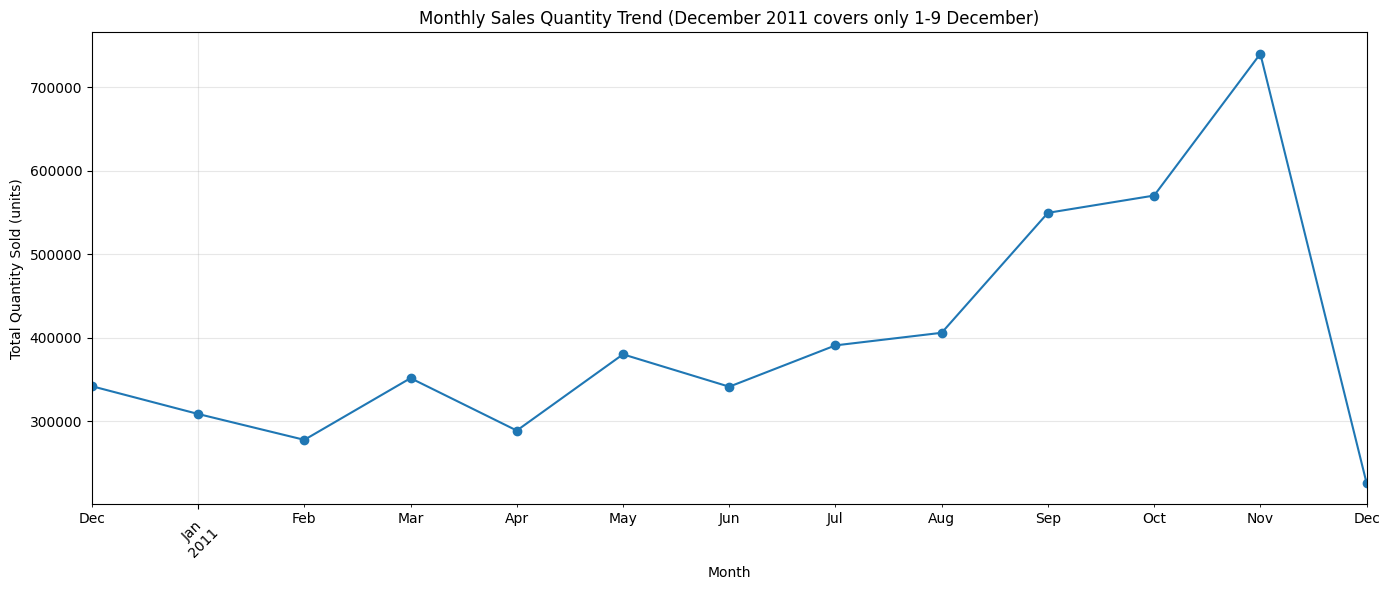

In [33]:
plt.figure(figsize=(14, 6))

monthly_quantity.plot(kind='line', marker='o')

plt.title('Monthly Sales Quantity Trend (December 2011 covers only 1-9 December)')
plt.xlabel('Month')
plt.ylabel('Total Quantity Sold (units)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Monthly Sales Quantity Insights

- Sales quantity fluctuated during the first eight months of the observed period.
- A noticeable increase in sales volume started in September 2011.
- November recorded the highest sales quantity, **740,286** units.
- The increase in quantity from September to November coincided with the increase in monthly revenue.
- December 2011 is incomplete, covering only the first nine days of the month.

**Note:** these quantities include negative quantity records, which may represent returns or other adjustments.

### Monthly Revenue Growth

Month-over-month growth is calculated from the monthly revenue above. The incomplete last month (December 2011) is excluded, because its change compared with a full month is not a real decline.

In [34]:
# The month of the last date in the data is incomplete (the data ends on 9 December 2011)
incomplete_month = df['InvoiceDate_dt'].max().to_period('M')

monthly_revenue_growth = monthly_revenue.pct_change() * 100
monthly_revenue_growth = monthly_revenue_growth.drop(incomplete_month)

display(monthly_revenue_growth.to_frame(name='Revenue Growth (%)'))

,Revenue Growth (%)
InvoiceDate_dt,
2010-12,NaN
2011-01,-25.229320
2011-02,-11.060282
2011-03,37.184967
2011-04,-27.816350
2011-05,46.659178
2011-06,-4.453048
2011-07,-1.421311
2011-08,0.202612


#### Monthly Revenue Growth Insights

- September 2011 recorded the highest month-over-month revenue growth, approximately 49.37%.
- May 2011 also showed strong growth, approximately 46.66%.
- April 2011 recorded the largest decline among the months shown, approximately 27.82%.
- Revenue remained relatively stable between June and August.
- Strong positive growth occurred in September and November.
- December 2011 is left out. Its raw change compared with November would be about -70%, but that only reflects nine days of data against a full month.

**Note:** growth rates are calculated from the previous month's recorded net line total. The data covers only about one year, so I cannot tell whether the September–November increase is a seasonal pattern or a general growth trend. Seasonal demand is one possible explanation, but I did not test it.

### Daily Revenue and Day-of-Week Patterns

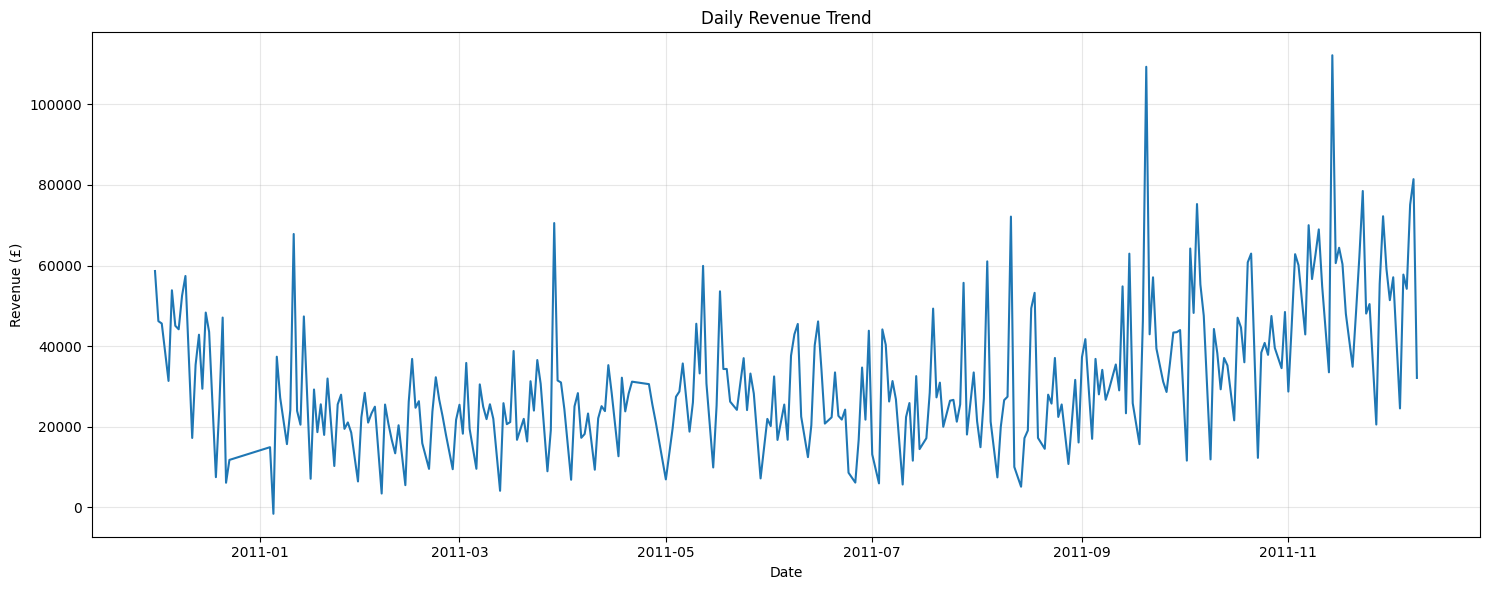

In [35]:
daily_revenue = (
    df.groupby(df['InvoiceDate_dt'].dt.date)['LineTotal']
    .sum()
)

plt.figure(figsize=(15, 6))

daily_revenue.plot()

plt.title('Daily Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue (£)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
daily_revenue_df = daily_revenue.copy()

daily_revenue_df.index = pd.to_datetime(daily_revenue_df.index)

daily_revenue_df.index.name = 'Date'

daily_revenue_df = daily_revenue_df.reset_index()

daily_revenue_df['DayOfWeek'] = daily_revenue_df['Date'].dt.day_name()

weekday_avg_revenue = (
    daily_revenue_df.groupby('DayOfWeek')['LineTotal']
    .mean()
)

In [37]:
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_avg_revenue = weekday_avg_revenue.reindex(weekday_order)

display(weekday_avg_revenue.to_frame(name='Average Daily Revenue'))

,Average Daily Revenue
DayOfWeek,
Monday,33800.200660
Tuesday,37811.207519
Wednesday,32719.754906
Thursday,39858.849057
Friday,30812.216220
Saturday,NaN
Sunday,16113.577820


In [38]:
# Number of days with at least one record, for each day of the week
daily_revenue_df['DayOfWeek'].value_counts().reindex(weekday_order, fill_value=0)

DayOfWeek
Monday       47
Tuesday      52
Wednesday    53
Thursday     53
Friday       50
Saturday      0
Sunday       50
Name: count, dtype: int64

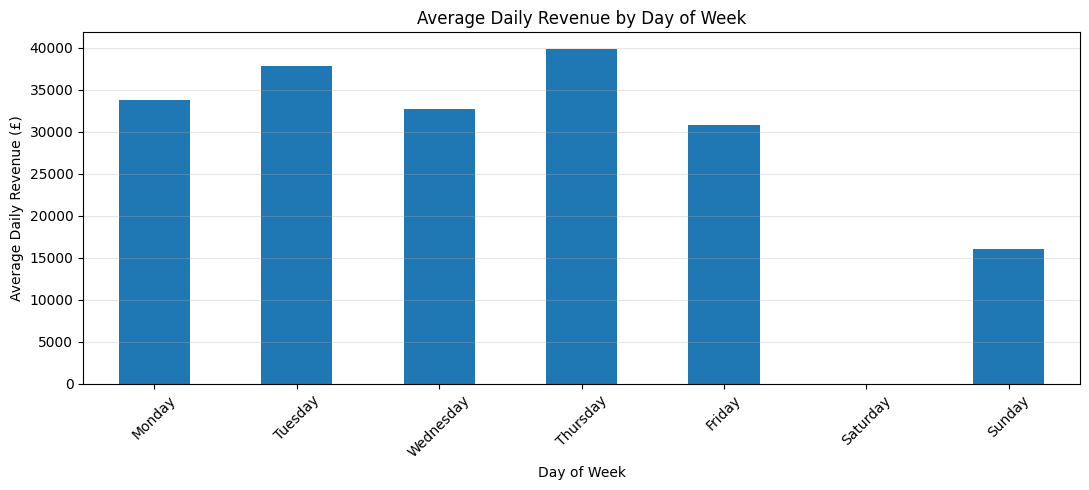

In [39]:
plt.figure(figsize=(11, 5))

weekday_avg_revenue.plot(kind='bar')

plt.title('Average Daily Revenue by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Daily Revenue (£)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Day-of-Week Revenue Insights

- Among the observed weekdays, Thursday recorded the highest average daily revenue (approximately 39,859) and Sunday the lowest (approximately 16,114).
- Tuesday also showed relatively strong average daily revenue.
- **There are no Saturday records at all** in the dataset (0 observed days). The data does not tell me why. The business may have been closed, or Saturday transactions may simply not be included. I do not assume either explanation.
- The other weekdays have between 47 and 53 observed days each. The averages only include days with at least one record, so days with no records are not counted as zero.

**Note:** these are descriptive observations of the available records, not conclusions about how the business operates.

### Hourly Revenue

In [40]:
df['Hour'] = df['InvoiceDate_dt'].dt.hour

hourly_revenue = (
    df.groupby('Hour')['LineTotal']
    .sum()
)

display(hourly_revenue.to_frame(name='Total Revenue'))

,Total Revenue
Hour,
6,-497.350
7,31009.320
8,281840.860
9,766734.051
10,1329056.521
11,1147437.920
12,1362484.290
13,1177506.370
14,1095212.901


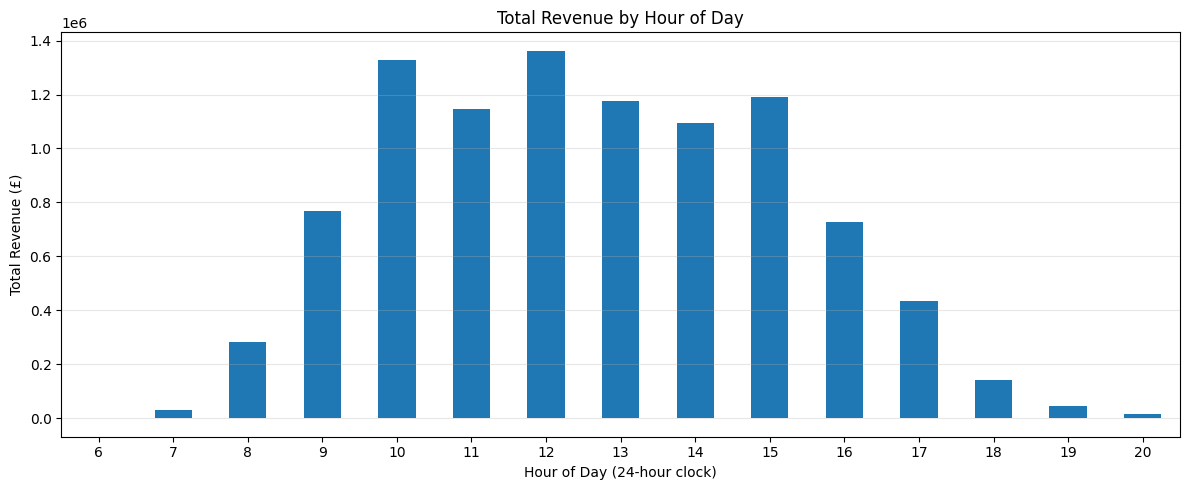

In [41]:
plt.figure(figsize=(12, 5))

hourly_revenue.plot(kind='bar')

plt.title('Total Revenue by Hour of Day')
plt.xlabel('Hour of Day (24-hour clock)')
plt.ylabel('Total Revenue (£)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Hourly Revenue Insights

- Revenue increased significantly from 8:00 onward.
- The highest recorded revenue occurred in the 12:00–12:59 hour, approximately 1.36 million.
- The period from 10:00 to 15:59 showed consistently high revenue.
- Revenue declined noticeably from 16:00 onward, and there was very little activity in the evening hours.
- A small negative value appeared at 6:00 (-497.35), which may reflect returns or adjustments.

**Note:** these are total recorded line values grouped by the hour of the timestamp, including negative quantities.

## 8. Geographical Analysis

Which countries account for the most records, revenue and quantity?

All rows are used. `Country` is the country where the customer resides, according to the dataset documentation. "Records" are product-line rows, not invoices or orders. Each top 10 list below is ranked by its own measure, so the countries are not exactly the same in every list.

In [42]:
country_records = (
    df['Country']
    .value_counts()
    .head(10)
)

display(country_records.to_frame(name='Line-Item Records'))

,Line-Item Records
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


In [43]:
country_revenue = (
    df.groupby('Country')['LineTotal']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_revenue.to_frame(name='Total Revenue'))

,Total Revenue
Country,
United Kingdom,8187806.364
Netherlands,284661.540
EIRE,263276.820
Germany,221698.210
France,197403.900
Australia,137077.270
Switzerland,56385.350
Spain,54774.580
Belgium,40910.960


In [44]:
country_quantity = (
    df.groupby('Country')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_quantity.to_frame(name='Total Quantity'))

,Total Quantity
Country,
United Kingdom,4263829
Netherlands,200128
EIRE,142637
Germany,117448
France,110480
Australia,83653
Sweden,35637
Switzerland,30325
Spain,26824


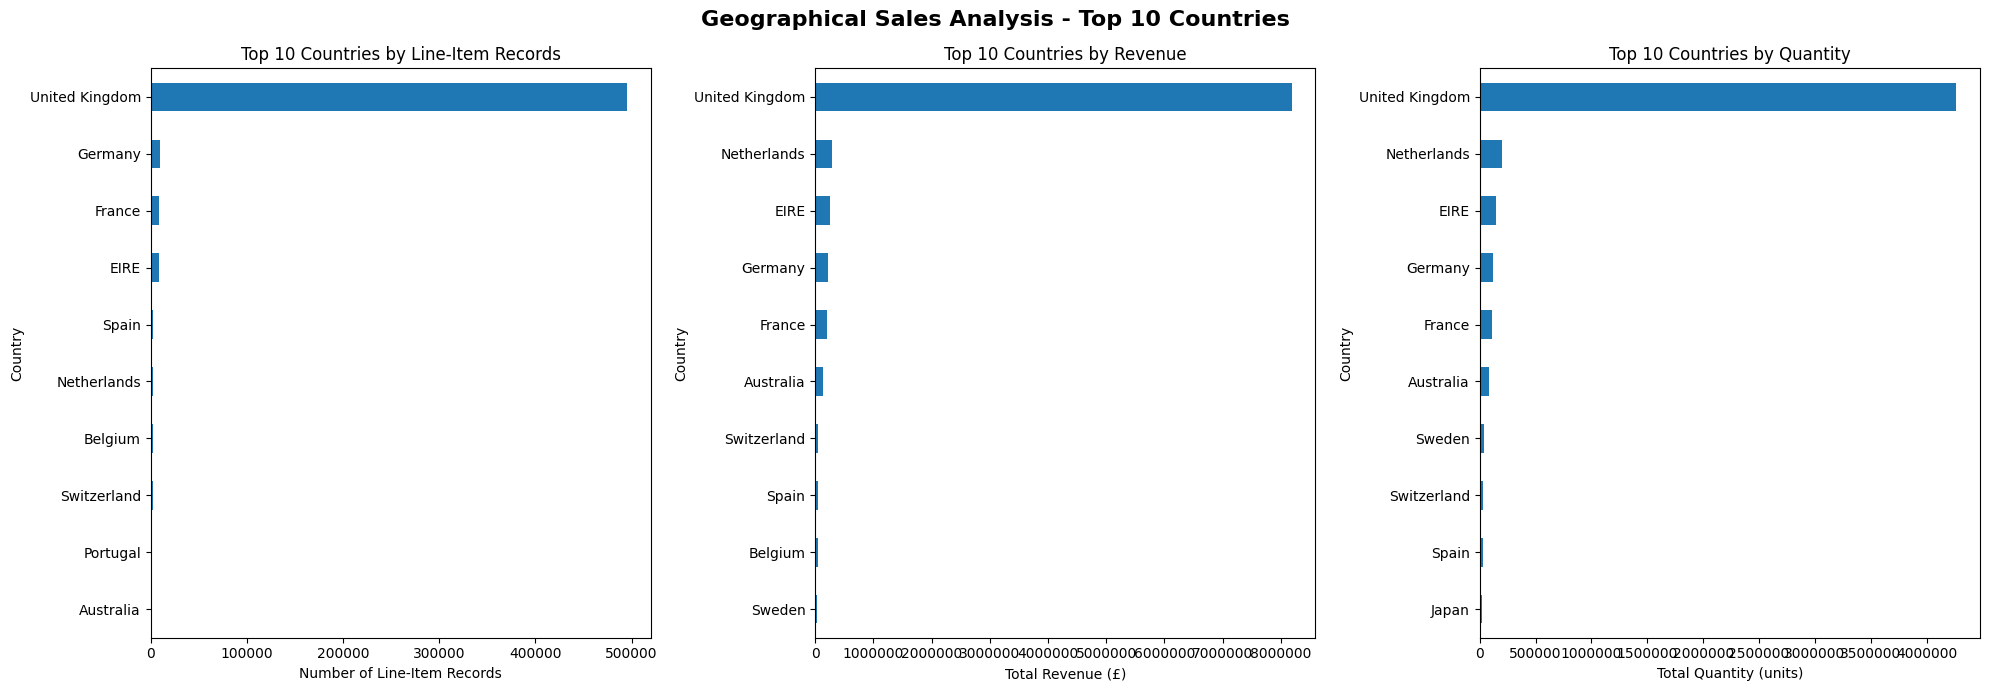

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Number of line-item records
country_records.plot(
    kind='barh',
    ax=axes[0]
)
axes[0].set_title('Top 10 Countries by Line-Item Records')
axes[0].set_xlabel('Number of Line-Item Records')
axes[0].invert_yaxis()

# 2. Total revenue
country_revenue.plot(
    kind='barh',
    ax=axes[1]
)
axes[1].set_title('Top 10 Countries by Revenue')
axes[1].set_xlabel('Total Revenue (£)')
axes[1].invert_yaxis()
axes[1].ticklabel_format(style='plain', axis='x')

# 3. Total quantity
country_quantity.plot(
    kind='barh',
    ax=axes[2]
)
axes[2].set_title('Top 10 Countries by Quantity')
axes[2].set_xlabel('Total Quantity (units)')
axes[2].invert_yaxis()
axes[2].ticklabel_format(style='plain', axis='x')

fig.suptitle(
    'Geographical Sales Analysis - Top 10 Countries',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

The United Kingdom is so much larger than every other country that the other bars are hard to see. The same three rankings are shown again below without the United Kingdom, using the same top 10 lists.

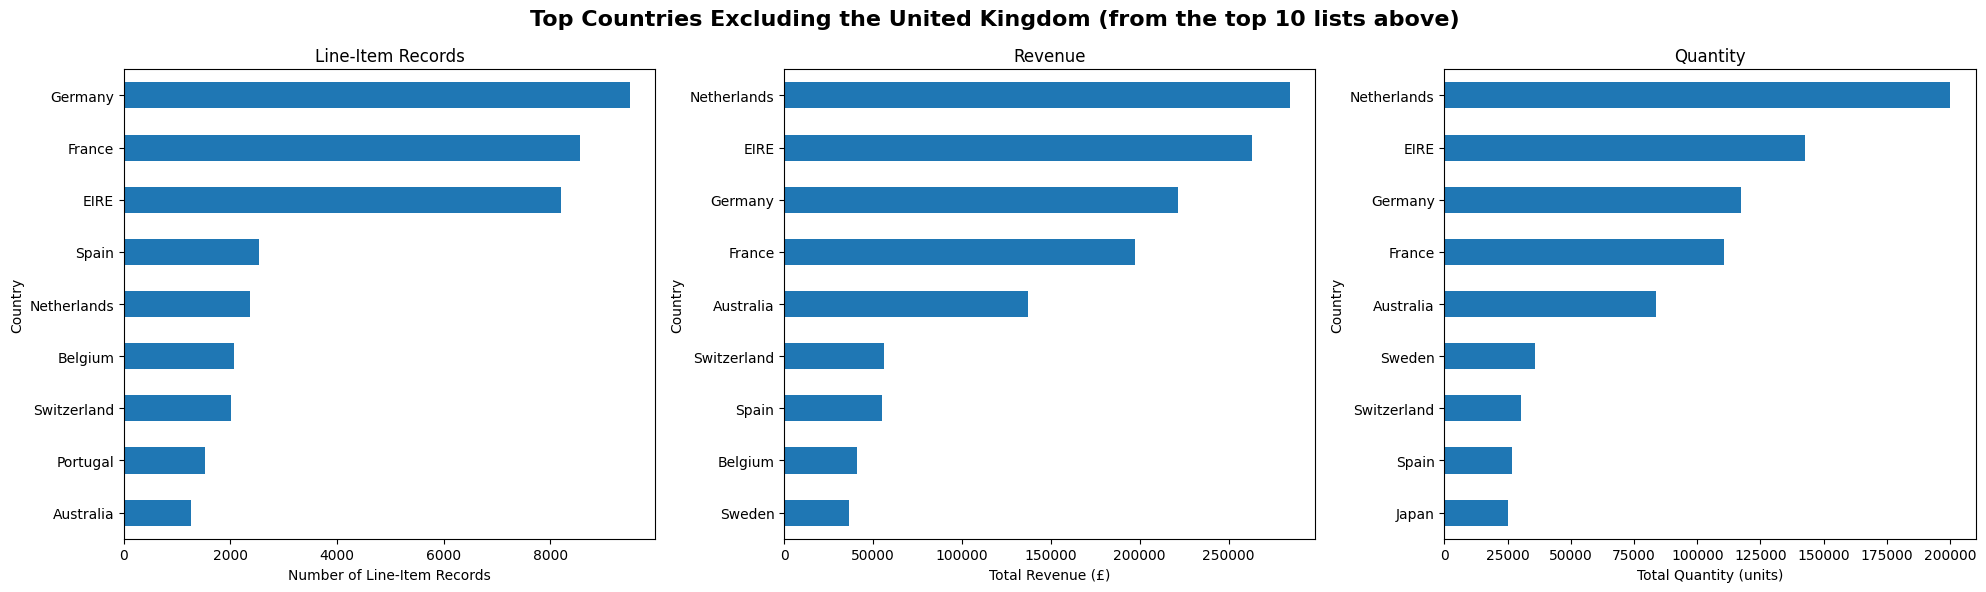

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Number of line-item records
country_records.drop('United Kingdom').plot(
    kind='barh',
    ax=axes[0]
)
axes[0].set_title('Line-Item Records')
axes[0].set_xlabel('Number of Line-Item Records')
axes[0].invert_yaxis()

# 2. Total revenue
country_revenue.drop('United Kingdom').plot(
    kind='barh',
    ax=axes[1]
)
axes[1].set_title('Revenue')
axes[1].set_xlabel('Total Revenue (£)')
axes[1].invert_yaxis()

# 3. Total quantity
country_quantity.drop('United Kingdom').plot(
    kind='barh',
    ax=axes[2]
)
axes[2].set_title('Quantity')
axes[2].set_xlabel('Total Quantity (units)')
axes[2].invert_yaxis()

fig.suptitle(
    'Top Countries Excluding the United Kingdom (from the top 10 lists above)',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [47]:
country_summary = pd.DataFrame({
    'Line_Item_Records': df['Country'].value_counts(),
    'Total_Quantity': df.groupby('Country')['Quantity'].sum()
})

country_summary['Quantity_Percentage'] = (
    country_summary['Total_Quantity'] /
    country_summary['Total_Quantity'].sum()
) * 100

country_summary['Records_Percentage'] = (
    country_summary['Line_Item_Records'] /
    country_summary['Line_Item_Records'].sum()
) * 100

country_summary.sort_values(
    'Total_Quantity',
    ascending=False
).head(10).round(2)

,Line_Item_Records,Total_Quantity,Quantity_Percentage,Records_Percentage
Country,,,,
United Kingdom,495478,4263829,82.37,91.43
Netherlands,2371,200128,3.87,0.44
EIRE,8196,142637,2.76,1.51
Germany,9495,117448,2.27,1.75
France,8557,110480,2.13,1.58
Australia,1259,83653,1.62,0.23
Sweden,462,35637,0.69,0.09
Switzerland,2002,30325,0.59,0.37
Spain,2533,26824,0.52,0.47


In [48]:
# Average net quantity per line-item record (net quantity divided by all records, including negative ones)
country_summary['Avg_Quantity_Per_Record'] = (
    country_summary['Total_Quantity'] /
    country_summary['Line_Item_Records']
)

country_summary.sort_values(
    'Avg_Quantity_Per_Record',
    ascending=False
).head(10).round(2)

,Line_Item_Records,Total_Quantity,Quantity_Percentage,Records_Percentage,Avg_Quantity_Per_Record
Country,,,,,
Netherlands,2371,200128,3.87,0.44,84.41
Sweden,462,35637,0.69,0.09,77.14
Japan,358,25218,0.49,0.07,70.44
Australia,1259,83653,1.62,0.23,66.44
Singapore,229,5234,0.10,0.04,22.86
Denmark,389,8188,0.16,0.07,21.05
Czech Republic,30,592,0.01,0.01,19.73
Lithuania,35,652,0.01,0.01,18.63
Canada,151,2763,0.05,0.03,18.30


### Geographical Sales Analysis Insights

- The United Kingdom dominates the dataset. It accounts for 91.43% of line-item records and 82.37% of total quantity.
- The Netherlands ranks second in both total revenue and total quantity (3.87% of quantity), even though it represents only 0.44% of records.
- Germany, France and EIRE have more records than the Netherlands, but lower total quantities.
- The difference between record shares and quantity shares reflects differences in the average quantity per line-item record across countries. The Netherlands has the highest average (about 84 units per record).
- Sales activity is highly concentrated in the United Kingdom, while the remaining countries each contribute a small share.

**Notes:** records are product-line rows, not unique invoices or orders. Averages for countries with very few records (for example the Czech Republic, with 30) rest on little data. Total quantity is a net value that includes negative quantities.

## 9. Unit Price Analysis

How are unit prices distributed, and what do the unusual prices (negative, zero and very high) look like?

All rows are used. Unusual prices are **not** removed. An unusual observation is not automatically a data error, so I look at what these rows actually are before drawing any conclusion.

In [49]:
df['UnitPrice'].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
1%            0.190000
5%            0.420000
25%           1.250000
50%           2.080000
75%           4.130000
95%           9.950000
99%          18.000000
max       38970.000000
Name: UnitPrice, dtype: float64

99th percentile of UnitPrice: 18.0


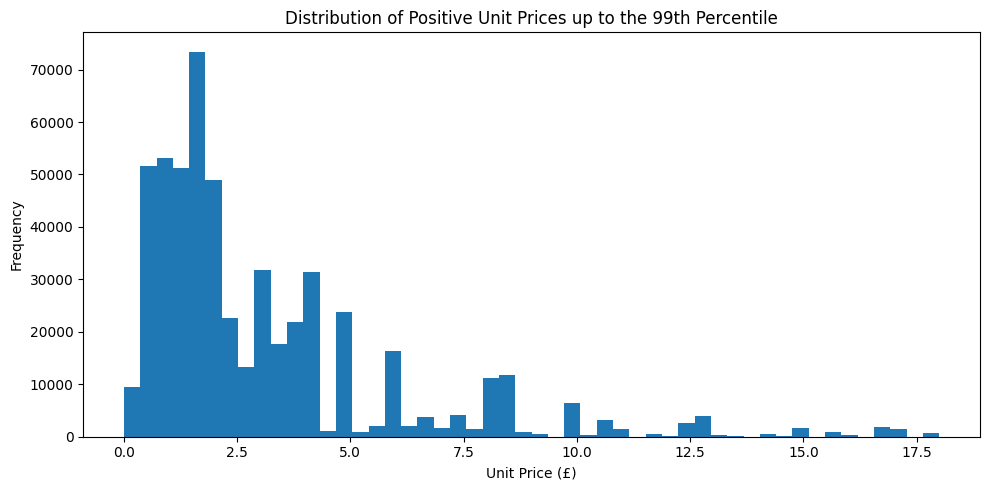

In [50]:
# 99th percentile of unit price, calculated from the data and reused below
price_99th = df['UnitPrice'].quantile(0.99)
print("99th percentile of UnitPrice:", price_99th)

# Histogram of positive prices up to the 99th percentile
# (the full range is too stretched by a few extreme values to read)
typical_prices = df.loc[
    (df['UnitPrice'] > 0) & (df['UnitPrice'] <= price_99th),
    'UnitPrice'
]

plt.figure(figsize=(10, 5))

plt.hist(typical_prices, bins=50)

plt.title('Distribution of Positive Unit Prices up to the 99th Percentile')
plt.xlabel('Unit Price (£)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [51]:
# Count unusual unit prices
price_counts = {
    'Negative Prices': (df['UnitPrice'] < 0).sum(),
    'Zero Prices': (df['UnitPrice'] == 0).sum(),
    'Positive Prices': (df['UnitPrice'] > 0).sum(),
    'Prices Above 99th Percentile': (df['UnitPrice'] > price_99th).sum()
}

pd.Series(price_counts)

Negative Prices                      2
Zero Prices                       2515
Positive Prices                 539392
Prices Above 99th Percentile      4790
dtype: int64

### Negative Prices

In [52]:
negative_price_rows = df[
    df['UnitPrice'] < 0
].sort_values('UnitPrice')

negative_price_rows[
    ['Description', 'Quantity', 'UnitPrice',
     'CustomerID', 'Country']
].head(15)

,Description,Quantity,UnitPrice,CustomerID,Country
299983,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,Adjust bad debt,1,-11062.06,NaN,United Kingdom


### Highest Prices (Top 30)

In [53]:
highest_price_rows = df.nlargest(
    30, 'UnitPrice'
)

highest_price_rows[
    ['Description', 'Quantity', 'UnitPrice',
     'CustomerID', 'Country']
]

,Description,Quantity,UnitPrice,CustomerID,Country
222681,Manual,-1,38970.00,15098.0,United Kingdom
524602,AMAZON FEE,-1,17836.46,NaN,United Kingdom
43702,AMAZON FEE,-1,16888.02,NaN,United Kingdom
43703,AMAZON FEE,-1,16453.71,NaN,United Kingdom
15016,AMAZON FEE,-1,13541.33,NaN,United Kingdom
15017,AMAZON FEE,1,13541.33,NaN,United Kingdom
16356,AMAZON FEE,-1,13541.33,NaN,United Kingdom
16232,AMAZON FEE,-1,13474.79,NaN,United Kingdom
524601,AMAZON FEE,-1,11586.50,NaN,United Kingdom
299982,Adjust bad debt,1,11062.06,NaN,United Kingdom


In [54]:
# What kinds of rows make up the 30 highest unit prices?
top_30_price_summary = (
    highest_price_rows
    .assign(QuantitySign=highest_price_rows['Quantity'].gt(0)
            .map({True: 'positive', False: 'negative'}))
    .groupby(['Description', 'QuantitySign'])
    .size()
    .rename('Rows')
    .reset_index()
    .sort_values('Rows', ascending=False)
)

display(top_30_price_summary)
print("Lowest price among these 30 rows:", highest_price_rows['UnitPrice'].min())

,Description,QuantitySign,Rows
0,AMAZON FEE,negative,24
3,Manual,negative,2
1,AMAZON FEE,positive,1
2,Adjust bad debt,positive,1
4,POSTAGE,negative,1
5,POSTAGE,positive,1


Lowest price among these 30 rows: 5258.77


The top 15 and top 30 lists agree on the first 15 rows. Extending to 30 adds information: rows 16 to 30 are one more `Manual` entry and `AMAZON FEE` rows, all with a negative quantity. Across the 30 highest prices, there are 25 `AMAZON FEE`, 2 `Manual`, 2 `POSTAGE` and 1 `Adjust bad debt` rows (counts taken from the original notebook's saved top-30 output; the cell above recomputes them). 27 of the 30 have a negative quantity. **No regular product appears among the 30 highest unit prices**; regular products with high prices only appear further down, among the rows above the 99th percentile (see below).

### Zero Prices

In [55]:
zero_price_rows = df[df['UnitPrice'] == 0]

print("Zero-price rows:", len(zero_price_rows))
print("Unique descriptions:", zero_price_rows['Description'].nunique())

zero_price_rows['Description'].value_counts().head(15)

Zero-price rows: 2515
Unique descriptions: 376


Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
Unsaleable, destroyed.             9
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
Found                              8
FRENCH BLUE METAL DOOR SIGN 8      8
amazon                             8
OWL DOORSTOP                       7
Name: count, dtype: int64

### Prices Above the 99th Percentile

In [56]:
high_price_rows = df[df['UnitPrice'] > price_99th]

print("High-price rows:", len(high_price_rows))

high_price_rows['Description'].value_counts().head(15)

High-price rows: 4790


Description
DOTCOM POSTAGE                      692
POSTAGE                             288
REGENCY CAKESTAND 3 TIER            247
Manual                              243
PICNIC BASKET WICKER LARGE          186
SET/4 WHITE RETRO STORAGE CUBES     163
CARRIAGE                            140
ENAMEL BREAD BIN CREAM              120
RED RETROSPOT CAKE STAND             97
BOTANICAL GARDENS WALL CLOCK         96
RED RETROSPOT ROUND CAKE TINS        85
CREAM SWEETHEART MINI CHEST          71
VICTORIAN SEWING BOX LARGE           61
REGENCY TEAPOT ROSES                 60
WOODEN CROQUET GARDEN SET            56
Name: count, dtype: int64

### Distribution of All Positive Prices (Log Scale)

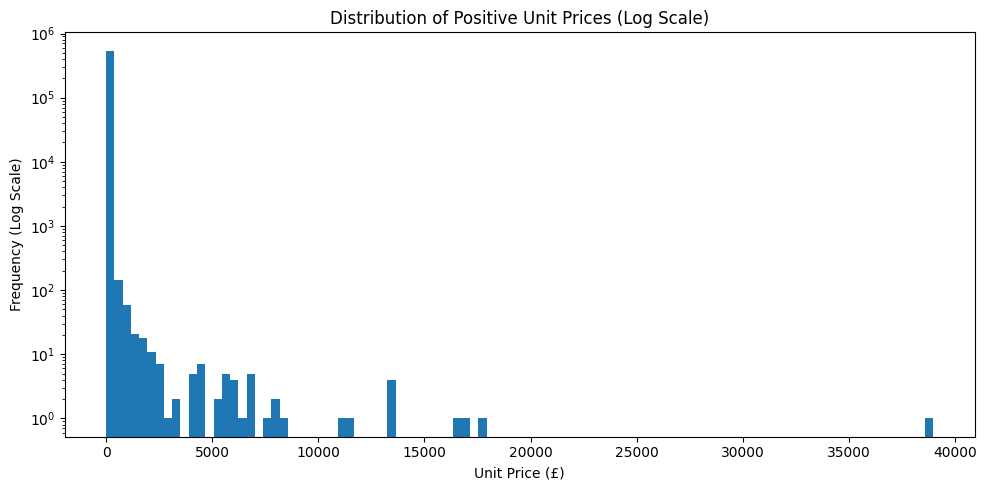

In [57]:
# Select positive unit prices for price distribution analysis
positive_prices = df.loc[
    df['UnitPrice'] > 0,
    'UnitPrice'
]

plt.figure(figsize=(10, 5))

plt.hist(positive_prices, bins=100)

plt.yscale('log')

plt.title('Distribution of Positive Unit Prices (Log Scale)')
plt.xlabel('Unit Price (£)')
plt.ylabel('Frequency (Log Scale)')
plt.tight_layout()
plt.show()

### Unit Price Insights

- Unit prices are strongly right-skewed. The mean is 4.61 and the median is 2.08. The 99th percentile is 18.00, while the maximum is 38,970.
- There are only **2** negative prices. Both rows are `Adjust bad debt` with a price of -11,062.06 and no `CustomerID`.
- There are **2,515** zero prices (about 0.46% of rows) across 376 different descriptions. Many descriptions look like manual stock notes (`check`, `damages`, `found`, `thrown away`), but others look like ordinary products (`FRENCH BLUE METAL DOOR SIGN 1`, `OWL DOORSTOP`). A zero price could mean a free item or a missing price. The data does not say which.
- **4,790** rows are above the 99th percentile. That is a statistical cutoff for "high", not a rule for "wrong".
- The most extreme prices are mostly non-product entries: `Manual`, `AMAZON FEE`, `Adjust bad debt` and `POSTAGE`. Several have negative quantities or no `CustomerID`, and some appear as a +1 and -1 pair with the same price (for example `AMAZON FEE` at 13,541.33 and `POSTAGE` at 8,142.75). That is consistent with a charge and its reversal, but I cannot confirm what these entries mean from this data.
- High prices are not only fees. Rows above the 99th percentile also include regular products with a high price, such as `REGENCY CAKESTAND 3 TIER` (247 rows) and `PICNIC BASKET WICKER LARGE` (186 rows).
- I did not find any row that I can confirm as a data error, so negative, zero and high prices were all kept. Whether to exclude them depends on the question being asked, and that decision belongs to a later cleaning step.

## 10. Key Findings

**Dataset and data quality**

- The dataset contains 541,909 records and 6 available columns, covering 1 December 2010 to 9 December 2011.
- `CustomerID` is missing in 135,080 rows (about 24.93%) and `Description` in 1,454 rows.
- Duplicate rows and rows with negative quantities were counted (Section 4) and not removed.
- There are 2 negative and 2,515 zero unit prices. Very high prices include fees, postage and manual entries. These were treated as unusual observations, not confirmed errors, and were not removed.

**Customers**

- There are 4,372 identified customers, with about 93 line items each on average. The top 10 customers have between 1,640 and 7,983 line items each.
- The customers with the most line items are not necessarily the top spenders: only three customers appear in both top 10 lists.
- Customer spending is the net sum of line totals, including negative quantities.

**Products**

- There are 4,077 unique product descriptions (positive quantities only).
- `PAPER CRAFT , LITTLE BIRDIE` ranks first by quantity (80,995 units, from a single line item) and third by revenue.
- `DOTCOM POSTAGE`, `Manual` and `POSTAGE` are in the top 10 by revenue, so the revenue ranking includes non-product entries.
- 424 descriptions (10.4%) recorded 10 units or fewer. This is an exploratory threshold, and the group includes non-product entries. 69 descriptions sold exactly one unit, so lowest-selling lists are arbitrary subsets of tied products.

**Time-based patterns**

- Monthly revenue and quantity both increased from September to November 2011, and November was the highest month. December 2011 is incomplete (the data ends on 9 December), so it was left out of the growth comparison.
- Among the observed weekdays, Thursday had the highest average daily revenue and Sunday the lowest. There are no Saturday records, and the reason is unknown.
- The highest recorded revenue by hour was in the 12:00–12:59 hour, and revenue was lower from 16:00 onward.
- These describe the available records only. With about one year of data, they cannot be called seasonal patterns.

**Countries**

- The United Kingdom accounts for 91.43% of line-item records and 82.37% of total quantity.
- The Netherlands ranks second by quantity and revenue while having only 0.44% of records, because its average quantity per record is high.

**Unit prices**

- Prices are strongly right-skewed (mean 4.61, median 2.08, 99th percentile 18.00, maximum 38,970).
- The 30 highest unit prices are all non-product entries (`AMAZON FEE`, `Manual`, `POSTAGE`, `Adjust bad debt`).

## 11. Limitations

- `InvoiceNo` and `StockCode` are not available in the retrieved DataFrame. Because of this, I could not analyze invoices, purchase frequency or cancellations, or group products by product code.
- Products are grouped by `Description`, so different descriptions of the same product count as separate items. Non-product entries (postage, fees, manual entries, adjustments) are included in the product rankings.
- Customer, monthly, weekday, hourly and country revenue include negative quantities. Product analysis uses positive quantities only. The numbers from these definitions should not be compared directly.
- Negative quantities cannot be confirmed as cancellations or returns.
- About a quarter of the rows have no `CustomerID`, so customer results describe only the identified customers.
- Duplicate rows were counted but not removed. Without `InvoiceNo` they cannot be classified as errors or legitimate repeated lines.
- The dataset covers about one year and ends mid-December 2011. Seasonality cannot be established.
- There are no Saturday records, and the reason is unknown.
- Lowest-selling lists are arbitrary subsets of tied products (ties broken alphabetically for reproducibility).

## 12. Final Conclusion

This EDA looked at customer, product, time-based, geographical and pricing patterns in the Online Retail dataset. It also showed why unusual values need business context before cleaning, since many of the largest prices and revenues come from fees, postage and adjustments rather than normal product sales.

The findings can be a starting point for further analysis. The limitations above should guide any cleaning or modeling work that follows.